# Analisis Error

Notebook ini mencari tahu **di mana dan kenapa model salah**. Ada dua jenis kesalahan:

| Singkatan | Nama | Artinya |
|---|---|---|
| **FN** | Churn terlewat | Pelanggan yang akhirnya churn, tetapi skornya di bawah threshold sehingga tidak dihubungi |
| **FP** | Salah hubungi | Pelanggan yang tidak churn, tetapi skornya di atas threshold sehingga ikut dihubungi |
| TP | Churn tertangkap | Pelanggan churn yang dihubungi |
| TN | Aman dan tidak dihubungi | Pelanggan tidak churn yang tidak dihubungi |

**Model:** XGBoost, parameter default, tanpa pembobotan, 12 fitur (keputusan 31). **Threshold:** default 1:5 dari `docs/threshold_skenario.csv` (keputusan 32). **Data:** hanya data latih, dan data uji tidak dipakai (keputusan 35).

Analisis ini **tidak mengubah model atau threshold**. Hasilnya dipakai untuk menulis keterbatasan dan menentukan hal yang perlu dipantau di Fase 6.

**Keterbatasan:** Analisis mengikuti dokumentasi UCI yang menyatakan tiap baris mewakili satu pelanggan. Audit menemukan pola berulang per 50 baris, sehingga independensi antarbaris tidak terjamin dan skor model bisa terlalu optimistis.

## 1. Persiapan

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.metrics import average_precision_score
from sklearn.model_selection import RepeatedStratifiedKFold, train_test_split
from xgboost import XGBClassifier

SEED = 180915
N_SPLITS = 5
N_REPEATS = 10
N_EXAMPLES = 3

# Path relatif terhadap root project
ROOT = Path.cwd().parent if Path.cwd().name == 'program' else Path.cwd()

Penanda baris janggal dihitung dengan definisi yang sama seperti Fase 1, pada seluruh data bersih, lalu jumlahnya dicek:

| Penanda | Definisi | Keputusan Fase 1 |
|---|---|---|
| Konflik label | Semua fitur sama persis dengan baris lain, tetapi `Churn` berbeda | 5 |
| `Charge_Amount` = 10 | Nilai di luar rentang dokumentasi UCI (0–9) | 6 |
| `Distinct_Called_Numbers` > `Frequency_of_use` | Jumlah nomor berbeda melebihi jumlah panggilan | 7 |
| Aktivitas nol | `Seconds_of_Use`, `Frequency_of_use`, dan `Frequency_of_SMS` semuanya 0 | 8 |
| `Subscription_Length` < 9 | Lama berlangganan di bawah 9 bulan | 9 |

In [2]:
df = pd.read_csv(ROOT / 'dataset_clean' / 'customer_churn_clean.csv')
groups = pd.read_csv(ROOT / 'dataset_clean' / 'validation_groups.csv')
assert len(groups) == len(df)

TARGET = 'Churn'
FEATURES = [col for col in df.columns if col not in (TARGET, 'Age_Binning')]
assert TARGET not in FEATURES and 'audit_group' not in FEATURES and 'Age_Binning' not in FEATURES
assert len(FEATURES) == 12

# Penanda baris janggal Fase 1, dihitung pada seluruh data bersih
all_inputs = [col for col in df.columns if col != TARGET]
FLAGS = {
    'Konflik label (keputusan 5)': df.groupby(all_inputs)[TARGET].transform('nunique') > 1,
    'Charge_Amount = 10 (keputusan 6)': df['Charge_Amount'] == 10,
    'Distinct_Called_Numbers > Frequency_of_use (keputusan 7)': df['Distinct_Called_Numbers'] > df['Frequency_of_use'],
    'Aktivitas nol (keputusan 8)': (df['Seconds_of_Use'] == 0) & (df['Frequency_of_use'] == 0) & (df['Frequency_of_SMS'] == 0),
    'Subscription_Length < 9 (keputusan 9)': df['Subscription_Length'] < 9,
}
expected = [28, 7, 111, 85, 54]
assert [int(flag.sum()) for flag in FLAGS.values()] == expected

# Pembagian yang sama dengan notebook sebelumnya. Data uji tidak dipakai di notebook ini
train_idx, _ = train_test_split(df.index, test_size=0.2, stratify=df[TARGET], random_state=SEED)
train = df.loc[train_idx].reset_index(drop=True)
X, y = train[FEATURES], train[TARGET].to_numpy()
flags = {name: flag.loc[train_idx].to_numpy() for name, flag in FLAGS.items()}
# Kelompok audit hanya untuk cek internal di bagian 6, bukan fitur model
audit_group = groups.loc[train_idx, 'audit_group'].to_numpy()
assert len(train) == 2280 and y.sum() == 357

thresholds = pd.read_csv(ROOT / 'docs' / 'threshold_skenario.csv').set_index('rasio')
RISK_THRESHOLD = float(thresholds.loc[thresholds['is_default']].iloc[0]['threshold'])
assert RISK_THRESHOLD == 0.06

print(f'Data latih: {len(train):,} baris, {y.sum():,} churn. Threshold: {RISK_THRESHOLD} (rasio 1:5)')

Data latih: 2,280 baris, 357 churn. Threshold: 0.06 (rasio 1:5)


## 2. Ringkasan kesalahan

Skor tiap pelanggan berasal dari model yang tidak melihat pelanggan itu saat dilatih (out-of-fold), diulang 10 kali. Seperti di `Risiko_Nilai.ipynb`, pelanggan disebut **diprediksi churn** jika skornya mencapai threshold di lebih dari separuh ulangan.

Selain itu, dihitung berapa kali tiap pelanggan salah dari 10 ulangan. Pelanggan yang **selalu salah** menunjukkan pola yang benar-benar tidak ditangkap model. Pelanggan yang **kadang salah** biasanya skornya dekat threshold.

In [3]:
def new_model():
    return XGBClassifier(random_state=SEED, eval_metric='logloss')


splits = list(RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=SEED + 1).split(X, y))
oof_scores = np.zeros((N_REPEATS, len(train)))
for repeat in range(N_REPEATS):
    for fit_idx, val_idx in splits[repeat * N_SPLITS:(repeat + 1) * N_SPLITS]:
        model = new_model().fit(X.iloc[fit_idx], y[fit_idx])
        oof_scores[repeat, val_idx] = model.predict_proba(X.iloc[val_idx])[:, 1]

repeat_pr = [average_precision_score(y, scores) for scores in oof_scores]
# Harus sama dengan notebook threshold dan risiko × nilai
assert round(min(repeat_pr), 3) == 0.923 and round(max(repeat_pr), 3) == 0.938

predicted = (oof_scores >= RISK_THRESHOLD).mean(axis=0) > 0.5
assert predicted.sum() == 464  # sama dengan Risiko_Nilai.ipynb
mean_score = oof_scores.mean(axis=0)
kind = np.select(
    [predicted & (y == 1), ~predicted & (y == 1), predicted & (y == 0)],
    ['TP', 'FN', 'FP'],
    default='TN',
)
counts = pd.Series(kind).value_counts().reindex(['TP', 'FN', 'FP', 'TN'])
assert counts['TP'] + counts['FN'] == y.sum() and counts.sum() == len(train)

# Berapa kali tiap pelanggan salah dari 10 ulangan
times_wrong = np.where(y == 1, (oof_scores < RISK_THRESHOLD).sum(axis=0), (oof_scores >= RISK_THRESHOLD).sum(axis=0))
stability = pd.DataFrame({
    'Selalu benar (0 dari 10)': [((times_wrong == 0) & (y == 1)).sum(), ((times_wrong == 0) & (y == 0)).sum()],
    'Kadang salah (1–9 dari 10)': [((times_wrong > 0) & (times_wrong < 10) & (y == 1)).sum(),
                                   ((times_wrong > 0) & (times_wrong < 10) & (y == 0)).sum()],
    'Selalu salah (10 dari 10)': [((times_wrong == 10) & (y == 1)).sum(), ((times_wrong == 10) & (y == 0)).sum()],
}, index=['Churn', 'Tidak churn'])

print(counts.rename({'TP': 'TP (churn tertangkap)', 'FN': 'FN (churn terlewat)',
                     'FP': 'FP (salah hubungi)', 'TN': 'TN (aman)'}).to_string())
print()
print(stability.to_string())

TP (churn tertangkap)     341
FN (churn terlewat)        16
FP (salah hubungi)        123
TN (aman)                1800

             Selalu benar (0 dari 10)  Kadang salah (1–9 dari 10)  Selalu salah (10 dari 10)
Churn                             314                          35                          8
Tidak churn                      1690                         177                         56


**Cara membaca:** salah hubungi (FP) jauh lebih banyak daripada churn terlewat (FN). Ini memang akibat rasio 1:5, yang menganggap churn terlewat lima kali lebih merugikan, sehingga threshold dibuat rendah. Tabel kedua memisahkan kesalahan yang selalu terjadi dari kesalahan yang hanya muncul di sebagian ulangan.

## 3. Seberapa yakin model saat salah

Kesalahan yang **dekat threshold** wajar dan bisa berubah jika threshold sedikit digeser. Kesalahan yang **jauh dari threshold** lebih serius, karena model yakin padahal salah.

               FN (churn terlewat)  FP (salah hubungi)
Minimum                      0.000               0.060
Kuartil bawah                0.001               0.160
Median                       0.012               0.290
Kuartil atas                 0.026               0.588
Maksimum                     0.100               0.961

FN dengan skor rata-rata di bawah separuh threshold (0.03): 13 dari 16
FP dengan skor rata-rata minimal 0,5: 38 dari 123


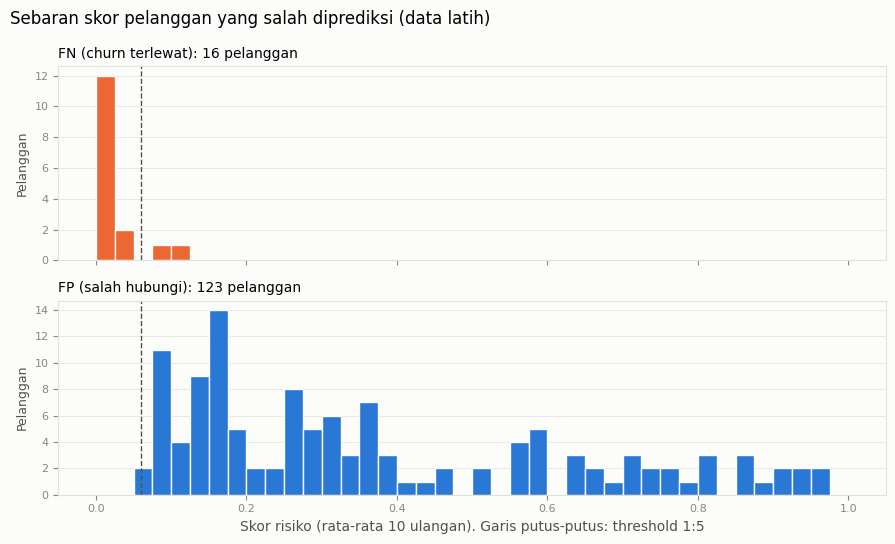

In [4]:
fn_scores, fp_scores = mean_score[kind == 'FN'], mean_score[kind == 'FP']
summary = pd.DataFrame({
    'FN (churn terlewat)': np.percentile(fn_scores, [0, 25, 50, 75, 100]),
    'FP (salah hubungi)': np.percentile(fp_scores, [0, 25, 50, 75, 100]),
}, index=['Minimum', 'Kuartil bawah', 'Median', 'Kuartil atas', 'Maksimum'])
print(summary.round(3).to_string())
print()
print(f'FN dengan skor rata-rata di bawah separuh threshold ({RISK_THRESHOLD / 2}): {(fn_scores < RISK_THRESHOLD / 2).sum()} dari {len(fn_scores)}')
print(f'FP dengan skor rata-rata minimal 0,5: {(fp_scores >= 0.5).sum()} dari {len(fp_scores)}')

ink_secondary, ink_muted, grid_color, surface = '#52514e', '#898781', '#e1e0d9', '#fcfcfb'
series = [('FN (churn terlewat)', fn_scores, '#eb6834'), ('FP (salah hubungi)', fp_scores, '#2a78d6')]
bins = np.linspace(0, 1, 41)
fig, axes = plt.subplots(2, 1, figsize=(9, 5.5), sharex=True, facecolor=surface)
for ax, (label, values, color) in zip(axes, series):
    ax.set_facecolor(surface)
    ax.hist(values, bins=bins, color=color, edgecolor=surface, linewidth=1)
    ax.axvline(RISK_THRESHOLD, color=ink_secondary, linewidth=1, linestyle='--')
    ax.set_title(f'{label}: {len(values)} pelanggan', loc='left', fontsize=10)
    ax.set_ylabel('Pelanggan', color=ink_secondary, fontsize=9)
    ax.tick_params(colors=ink_muted, labelsize=8)
    for spine in ax.spines.values():
        spine.set_color(grid_color)
    ax.grid(axis='y', color=grid_color, linewidth=0.5)
    ax.set_axisbelow(True)
axes[1].set_xlabel('Skor risiko (rata-rata 10 ulangan). Garis putus-putus: threshold 1:5', color=ink_secondary)
fig.suptitle('Sebaran skor pelanggan yang salah diprediksi (data latih)', x=0.01, ha='left', fontsize=12)
plt.tight_layout()
plt.show()

**Cara membaca:** batang oranye di sebelah kiri garis adalah churn terlewat. Makin dekat ke 0, makin yakin model bahwa pelanggan itu aman, padahal akhirnya churn. Batang biru di sebelah kanan garis adalah salah hubungi. Makin dekat ke 1, makin yakin model bahwa pelanggan itu akan churn, padahal tidak.

Beberapa batang bisa berada sedikit di seberang garis. Kategori FN dan FP memakai suara mayoritas dari 10 ulangan, sedangkan grafik memakai rata-rata skor, jadi pelanggan yang skornya sangat dekat threshold bisa tampak di sisi lain.

## 4. Profil pelanggan yang salah

Tabel ini membandingkan ciri pelanggan di keempat kelompok. Untuk kolom ya atau tidak dipakai porsi, dan untuk kolom angka dipakai median, supaya tidak terpengaruh nilai ekstrem.

In [5]:
profile = pd.DataFrame({
    'Pelanggan': pd.Series(kind).value_counts(),
    'Pernah komplain': pd.Series(train['Complains'] == 1).groupby(kind).mean(),
    'Non-aktif': pd.Series(train['Status'] == 2).groupby(kind).mean(),
    'Median Frequency_of_use': train['Frequency_of_use'].groupby(kind).median(),
    'Median Seconds_of_Use': train['Seconds_of_Use'].groupby(kind).median(),
    'Median Call_Failure': train['Call_Failure'].groupby(kind).median(),
    'Median Subscription_Length': train['Subscription_Length'].groupby(kind).median(),
    'Median Customer_Value': train['Customer_Value'].groupby(kind).median(),
}).reindex(['TP', 'FN', 'FP', 'TN'])
shown = profile.copy()
for col in ('Pernah komplain', 'Non-aktif'):
    shown[col] = (100 * shown[col]).round(1).astype(str) + '%'
print(shown.round(1).to_string())

    Pelanggan Pernah komplain Non-aktif  Median Frequency_of_use  Median Seconds_of_Use  Median Call_Failure  Median Subscription_Length  Median Customer_Value
TP        341           45.2%     75.4%                     27.0                 1243.0                  6.0                        35.0                  100.9
FN         16            0.0%     37.5%                     24.5                 1635.5                  5.0                        36.0                  129.7
FP        123            6.5%     77.2%                     14.0                  703.0                  5.0                        36.0                   79.0
TN       1800            1.3%     10.4%                     67.0                 3925.0                  6.0                        35.0                  300.4


**Cara membaca:** bandingkan FN dengan TP, dan FP dengan TN.

- Jika **FN** lebih mirip **TN** daripada TP, churn terlewat adalah pelanggan yang tampak aman di data. Model tidak punya sinyal untuk mereka.
- Jika **FP** lebih mirip **TP**, salah hubungi adalah pelanggan yang tampak berisiko, tetapi ternyata bertahan.

Ini pola dari data, bukan alasan pelanggan bertahan atau pergi.

## 5. Kaitan dengan baris janggal Fase 1

Fase 1 memutuskan untuk **mempertahankan** beberapa jenis baris janggal (keputusan 5–9). Bagian ini memeriksa apakah model lebih sering salah pada baris-baris itu.

Catatan khusus untuk **konflik label**: jika dua baris punya fitur yang sama persis tetapi label berbeda, model akan memberi skor yang sama untuk keduanya. Jadi paling tidak salah satunya pasti salah. Ini kesalahan yang **tidak bisa dihindari** oleh model mana pun.

In [6]:
error = (kind == 'FN') | (kind == 'FP')
rows = []
for name, flag in flags.items():
    rows.append({
        'Penanda': name,
        'Baris di data latih': flag.sum(),
        'Salah': error[flag].sum(),
        'Tingkat salah': error[flag].mean() if flag.sum() else np.nan,
        'Tingkat salah baris lain': error[~flag].mean(),
        'FN': ((kind == 'FN') & flag).sum(),
        'FP': ((kind == 'FP') & flag).sum(),
    })
flag_table = pd.DataFrame(rows).set_index('Penanda')
shown = flag_table.copy()
for col in ('Tingkat salah', 'Tingkat salah baris lain'):
    shown[col] = (100 * shown[col]).round(1).astype(str) + '%'
print(shown.to_string())

any_flag = np.any(list(flags.values()), axis=0)
print()
print(f'Kesalahan pada baris berpenanda: {error[any_flag].sum()} dari {error.sum()} ({error[any_flag].sum() / error.sum():.0%})')

                                                          Baris di data latih  Salah Tingkat salah Tingkat salah baris lain  FN  FP
Penanda                                                                                                                            
Konflik label (keputusan 5)                                                24     15         62.5%                     5.5%   2  13
Charge_Amount = 10 (keputusan 6)                                            5      0          0.0%                     6.1%   0   0
Distinct_Called_Numbers > Frequency_of_use (keputusan 7)                   99     10         10.1%                     5.9%   1   9
Aktivitas nol (keputusan 8)                                                68     17         25.0%                     5.5%   0  17
Subscription_Length < 9 (keputusan 9)                                      48      0          0.0%                     6.2%   0   0

Kesalahan pada baris berpenanda: 32 dari 139 (23%)


**Cara membaca:** bandingkan **tingkat salah** dengan **tingkat salah baris lain**. Jika jauh lebih tinggi, baris janggal itu menjadi sumber kesalahan model. Keputusan Fase 1 untuk mempertahankan baris-baris ini tetap berlaku. Temuan ini hanya menunjukkan bahwa sebagian kesalahan berasal dari data yang memang janggal atau tidak konsisten.

## 6. Cek internal: kesalahan per kelompok audit

Kelompok audit adalah sisa bagi 50 dari posisi baris di file mentah, dan pelanggan dalam satu kelompok cenderung sangat mirip (audit Fase 1). Kelompok ini tidak pernah dipakai sebagai fitur model. Jika kesalahan terpusat di sedikit kelompok, sebagian besar kesalahan berasal dari pola berulang tertentu, bukan tersebar acak.

In [7]:
error_by_group = pd.Series(error).groupby(audit_group).sum()
groups_with_error = error_by_group[error_by_group > 0].sort_values(ascending=False)
top3_share = groups_with_error.head(3).sum() / error.sum()
print(f'Kesalahan berasal dari {len(groups_with_error)} dari 50 kelompok audit. '
      f'3 kelompok teratas menyumbang {top3_share:.0%}.')

group_profile = pd.DataFrame({
    'FP': pd.Series(kind == 'FP').groupby(audit_group).sum(),
    'FN': pd.Series(kind == 'FN').groupby(audit_group).sum(),
    'Pelanggan di kelompok': pd.Series(y).groupby(audit_group).size(),
    'Churn rate kelompok': pd.Series(y).groupby(audit_group).mean(),
    'Non-aktif di kelompok': pd.Series(train['Status'] == 2).groupby(audit_group).mean(),
    'Komplain di kelompok': pd.Series(train['Complains'] == 1).groupby(audit_group).mean(),
})
top_fp = group_profile.sort_values('FP', ascending=False).head(5)
top_fp.index.name = 'Kelompok audit'
shown = top_fp.copy()
for col in ('Churn rate kelompok', 'Non-aktif di kelompok', 'Komplain di kelompok'):
    shown[col] = (100 * shown[col]).round(1).astype(str) + '%'
print()
print('Lima kelompok penyumbang salah hubungi (FP) terbanyak:')
print(shown.to_string())
print()
print(f'Kelima kelompok ini menyumbang {top_fp["FP"].sum()} dari {(kind == "FP").sum()} FP.')

Kesalahan berasal dari 20 dari 50 kelompok audit. 3 kelompok teratas menyumbang 45%.

Lima kelompok penyumbang salah hubungi (FP) terbanyak:
                FP  FN  Pelanggan di kelompok Churn rate kelompok Non-aktif di kelompok Komplain di kelompok
Kelompok audit                                                                                              
1               35   0                     41                2.4%                 92.7%                 2.4%
17              14   0                     42                0.0%                 97.6%                 0.0%
11              13   0                     40                0.0%                 95.0%                25.0%
40              13   0                     43                2.3%                 95.3%                 2.3%
16               9   1                     50                2.0%                 98.0%                 0.0%

Kelima kelompok ini menyumbang 84 dari 123 FP.


**Cara membaca:** perhatikan ciri kelompok penyumbang FP terbanyak. Jika sebagian besar pelanggannya **non-aktif** tetapi **hampir tidak ada yang churn**, model membaca status non-aktif sebagai tanda churn, padahal di kelompok itu tidak demikian. Cara `Status` ditentukan tidak dijelaskan UCI (keputusan 29), jadi hubungan status non-aktif dengan churn perlu dibaca hati-hati.

## 7. Contoh: churn terlewat yang selalu salah

Tiga pelanggan churn yang **selalu** terlewat di 10 ulangan dipilih, yaitu yang skor rata-ratanya paling rendah. Untuk masing-masing, model dari ulangan pertama yang **tidak melihat pelanggan itu saat dilatih** dijelaskan dengan SHAP bawaan XGBoost. Hasilnya menunjukkan fitur mana yang paling menurunkan skornya.

SHAP dalam satuan log-odds: negatif berarti menurunkan skor risiko, dan positif menaikkannya. Penjelasan ini menggambarkan cara model bekerja, bukan alasan pelanggan churn.

In [8]:
always_missed = np.where((y == 1) & (times_wrong == 10))[0]
examples = always_missed[np.argsort(mean_score[always_missed], kind='stable')[:N_EXAMPLES]]
first_repeat = splits[:N_SPLITS]

for number, row in enumerate(examples, start=1):
    fit_idx = next(fit for fit, val in first_repeat if row in val)
    assert row not in fit_idx
    model = new_model().fit(X.iloc[fit_idx], y[fit_idx])
    drow = xgb.DMatrix(X.iloc[[row]])
    contribs = model.get_booster().predict(drow, pred_contribs=True)[0]
    margin = model.get_booster().predict(drow, output_margin=True)[0]
    # Jumlah sumbangan semua fitur ditambah nilai dasar harus sama dengan skor model (log-odds)
    assert np.isclose(contribs.sum(), margin, atol=1e-4)
    score = model.predict_proba(X.iloc[[row]])[0, 1]
    top = pd.DataFrame({'Nilai fitur': X.iloc[row], 'Sumbangan SHAP': contribs[:-1]}, index=FEATURES)
    top = top.reindex(top['Sumbangan SHAP'].abs().sort_values(ascending=False).index).head(5)
    print(f'Contoh {number}: skor {score:.4f} (threshold {RISK_THRESHOLD}), kelompok audit {audit_group[row]}, '
          f'nilai dasar {contribs[-1]:+.2f}')
    print(top.round(2).to_string())
    print()

Contoh 1: skor 0.0002 (threshold 0.06), kelompok audit 24, nilai dasar -2.04
                         Nilai fitur  Sumbangan SHAP
Frequency_of_use                82.0           -2.69
Status                           1.0           -1.44
Distinct_Called_Numbers          7.0           -0.94
Call_Failure                     4.0           -0.86
Complains                        0.0           -0.68



Contoh 2: skor 0.0002 (threshold 0.06), kelompok audit 49, nilai dasar -2.01
                     Nilai fitur  Sumbangan SHAP
Subscription_Length        17.00           -2.16
Status                      1.00           -1.63
Customer_Value            171.52           -0.95
Complains                   0.00           -0.70
Call_Failure               13.00            0.62



Contoh 3: skor 0.0004 (threshold 0.06), kelompok audit 16, nilai dasar -2.02
                         Nilai fitur  Sumbangan SHAP
Call_Failure                     0.0           -2.66
Distinct_Called_Numbers         11.0           -1.16
Status                           2.0            1.12
Age_Group                        2.0           -1.11
Seconds_of_Use                 875.0           -0.84



**Cara membaca:** kolom **Sumbangan SHAP** menunjukkan seberapa besar tiap fitur mendorong skor pelanggan itu. Jika fitur teratas bernilai negatif, misalnya status aktif, tidak pernah komplain, atau pemakaian tinggi, pelanggan itu tampak seperti pelanggan aman di data. Model tidak punya sinyal yang memisahkannya dari pelanggan yang benar-benar bertahan.

## Cara membaca hasil

**Ringkasnya:**

- Kebanyakan kesalahan adalah salah hubungi. Ini memang akibat rasio 1:5.
- Churn terlewat sedikit, tetapi umumnya "yakin salah": pelanggan itu tampak aman di semua sinyal yang dipakai model.
- Sebagian kesalahan berasal dari baris janggal yang dipertahankan di Fase 1. Kesalahan pada baris dengan konflik label tidak bisa dihindari.
- Salah hubungi terpusat pada beberapa kelompok audit yang hampir seluruhnya non-aktif tetapi tidak churn.

**Untuk pemantauan Fase 6** (usulan, belum diputuskan):

- Porsi pelanggan tanpa aktivitas, karena model menganggap mereka semua berisiko.
- Porsi pelanggan non-aktif tanpa komplain, karena di sini sumber salah hubungi terbesar.
- Pelanggan churn yang skornya sangat rendah, jika label churn sudah tersedia.

**Keterbatasan:**

1. **Hanya data latih dengan CV acak.** Pola kesalahan pada pelanggan baru bisa berbeda.
2. **Penanda baris janggal mengikuti definisi Fase 1,** dan satu baris bisa punya lebih dari satu penanda.
3. **Konflik label tidak bisa dihindari** oleh model mana pun.
4. **SHAP menjelaskan cara model bekerja, bukan sebab churn.**
5. **Model dan threshold tidak diubah** berdasarkan analisis ini (keputusan 31, 32, dan 35).